<a href="https://colab.research.google.com/github/Jorgellamocca/S2S-PER/blob/main/viento_costero.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Abriendo catálogo ECMWF...

Variables verificadas.

UNIDADES ORIGINALES
Temperatura: degree_celsius
Humedad específica: 1
Viento U: ms-1
Viento V: ms-1

Calculando seis semanas...
SEMANA 1 | 20/10 - 26/10/2026 | HR media: 37.1% | Viento medio: 9.1 m/s
SEMANA 2 | 27/10 - 02/11/2026 | HR media: 34.8% | Viento medio: 8.4 m/s
SEMANA 3 | 03/11 - 09/11/2026 | HR media: 36.7% | Viento medio: 8.2 m/s
SEMANA 4 | 10/11 - 16/11/2026 | HR media: 37.1% | Viento medio: 8.0 m/s
SEMANA 5 | 17/11 - 23/11/2026 | HR media: 37.1% | Viento medio: 7.9 m/s
SEMANA 6 | 24/11 - 30/11/2026 | HR media: 36.6% | Viento medio: 7.8 m/s


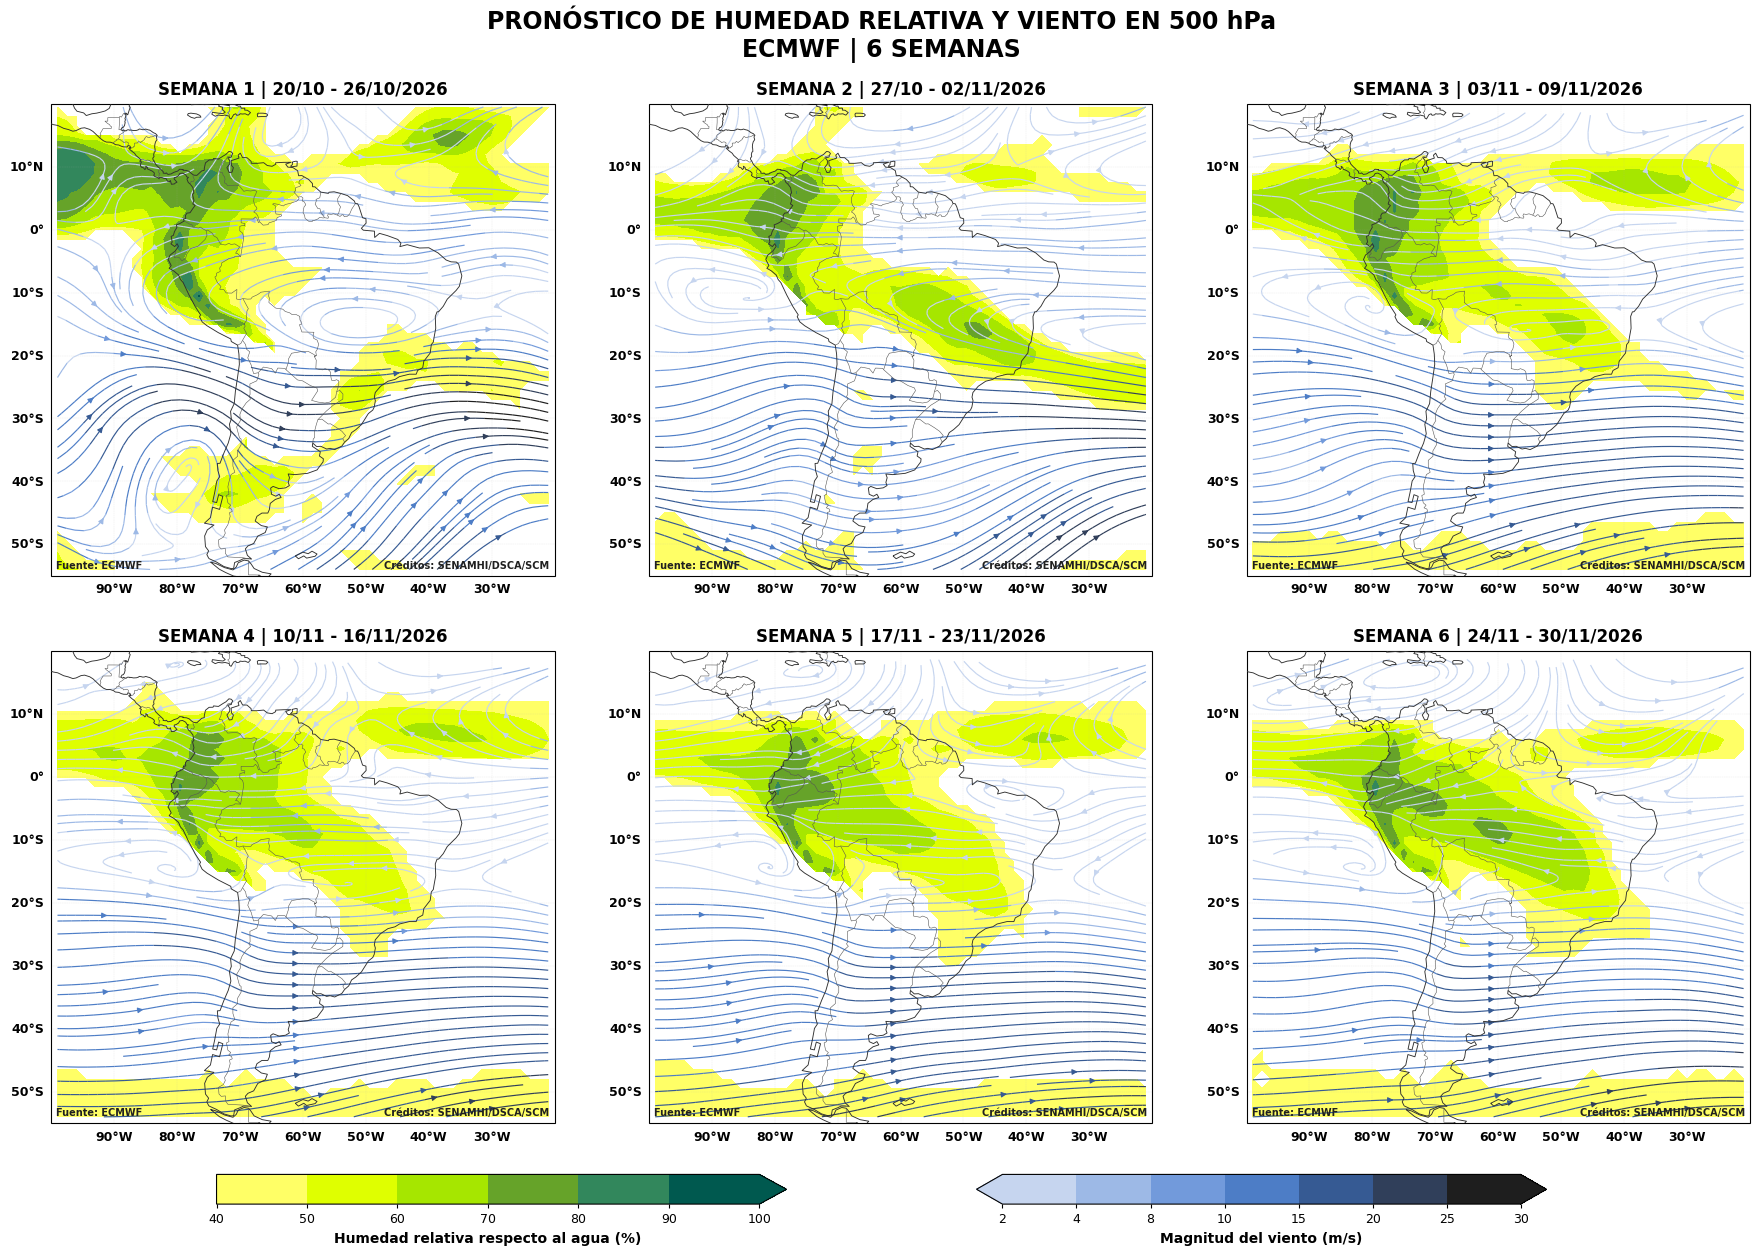


PROCESAMIENTO COMPLETADO
Fuente: ECMWF
Inicialización: 2026-10-19 00:00:00
Nivel: 500 hPa
Semanas: 6
HR: calculada por miembro y día
HR: respecto al agua
Viento: promedio vectorial semanal
Figura: /content/ECMWF_HR_VIENTO_200HPA/ECMWF_HR_VIENTO_500hPa_6SEMANAS_20261019.png


In [6]:
# ================================================================
# ECMWF | PRONÓSTICO SUBESTACIONAL
# HUMEDAD RELATIVA Y VIENTO EN 200 hPa
#
# 6 SEMANAS | UNA SOLA FIGURA PNG
#
# HR: calculada por día y miembro, luego promediada
# Viento: promedio de U y V, luego magnitud resultante
# HR respecto al agua (Murphy & Koop, 2005)
#
# Fuente: ECMWF
# Créditos: SENAMHI/DSCA/SCM
# ================================================================

# GOOGLE COLAB
%pip install -q dynamical-catalog cartopy scipy netcdf4

import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.interpolate import RegularGridInterpolator
from matplotlib.cm import ScalarMappable

# ================================================================
# 1. CONFIGURACIÓN
# ================================================================

CATALOGO = (
    "ecmwf-ifs-ens-forecast-46-day-daily-1-5-degree"
)

NIVEL = 500     #cambiar a 200

LON_MIN, LON_MAX = -100, -20
LAT_MIN, LAT_MAX = -55, 20

N_SEMANAS = 6
DIAS_SEMANA = 7

# Densidad gráfica de las líneas
DENSIDAD = 1.8

# Resolución para visualizar streamlines
RESOLUCION_GRAFICA = 0.5

# Escalas
NIVELES_HR = np.array(
    [40, 50, 60, 70, 80, 90, 100]
)

NIVELES_VIENTO = np.array(
    [2, 4, 8, 10, 15, 20, 25, 30]
)

# Directorio
OUTPUT_DIR = "/content/ECMWF_HR_VIENTO_200HPA"

os.makedirs(OUTPUT_DIR, exist_ok=True)

FUENTE = "Fuente: ECMWF"
CREDITOS = "Créditos: SENAMHI/DSCA/SCM"

# ================================================================
# 2. ABRIR CATÁLOGO
# ================================================================

import dynamical_catalog

print("Abriendo catálogo ECMWF...")

ds = dynamical_catalog.open(
    CATALOGO,
    group="pressure_level",
    chunks=None
)

VARIABLES = [
    "wind_u",
    "wind_v",
    "temperature",
    "specific_humidity"
]

for var in VARIABLES:
    if var not in ds:
        raise ValueError(
            f"Variable no disponible: {var}"
        )

print("\nVariables verificadas.")

# ================================================================
# 3. INICIALIZACIÓN Y NIVEL
# ================================================================

INIT_TIME = ds.init_time.values[-1]
INIT = pd.Timestamp(INIT_TIME)

if NIVEL not in ds.pressure_level.values:
    raise ValueError(
        f"Nivel {NIVEL} hPa no disponible"
    )

datos = ds[VARIABLES].sel(
    init_time=INIT_TIME,
    pressure_level=NIVEL
)

# ================================================================
# 4. COORDENADAS
# ================================================================

if float(datos.longitude.max()) > 180:

    datos = datos.assign_coords(
        longitude=(
            (datos.longitude + 180) % 360
        ) - 180
    )

datos = datos.sortby("longitude")
datos = datos.sortby("latitude")

datos = datos.sel(
    longitude=slice(LON_MIN, LON_MAX),
    latitude=slice(LAT_MIN, LAT_MAX)
)

# ================================================================
# 5. SELECCIONAR 42 DÍAS
# ================================================================

plazos = pd.timedelta_range(
    start="1D",
    periods=N_SEMANAS * DIAS_SEMANA,
    freq="D"
)

disponibles = pd.to_timedelta(
    datos.lead_time.values
)

faltantes = plazos.difference(disponibles)

if len(faltantes):
    raise ValueError(
        f"Faltan plazos diarios: {faltantes}"
    )

datos = datos.sel(
    lead_time=plazos
)

# ================================================================
# 6. VERIFICAR UNIDADES
# ================================================================

def obtener_unidades(da):
    return str(
        da.attrs.get("units", "")
    ).strip().lower().replace(" ", "")


unidad_t = obtener_unidades(datos["temperature"])
unidad_q = obtener_unidades(datos["specific_humidity"])
unidad_u = obtener_unidades(datos["wind_u"])
unidad_v = obtener_unidades(datos["wind_v"])

print("\nUNIDADES ORIGINALES")
print("Temperatura:", unidad_t)
print("Humedad específica:", unidad_q)
print("Viento U:", unidad_u)
print("Viento V:", unidad_v)

UNIDADES_K = {
    "k", "kelvin", "degk", "degree_kelvin"
}

UNIDADES_C = {
    "c", "degc", "celsius",
    "degree_celsius", "degrees_celsius", "°c"
}

UNIDADES_Q = {
    "kg/kg", "kgkg-1", "kgkg^-1", "1"
}

UNIDADES_V = {
    "m/s", "ms-1", "ms^-1", "m*s-1"
}

if unidad_t not in UNIDADES_K | UNIDADES_C:
    raise ValueError(
        f"Revisar unidades de temperatura: {unidad_t}"
    )

if unidad_q not in UNIDADES_Q:
    raise ValueError(
        f"Revisar unidades de humedad específica: {unidad_q}"
    )

if unidad_u not in UNIDADES_V or unidad_v not in UNIDADES_V:
    raise ValueError(
        "Revisar unidades de viento U/V"
    )

# ================================================================
# 7. HUMEDAD RELATIVA RESPECTO AL AGUA
# ================================================================

def calcular_hr_agua(q, temperatura, nivel_hpa):
    """
    q: humedad específica en kg/kg
    temperatura: Kelvin
    nivel_hpa: hPa

    Presión de saturación respecto al agua:
    Murphy & Koop (2005).

    Retorna humedad relativa (%) sin limitar
    artificialmente los valores superiores a 100.
    """

    T = np.asarray(temperatura, dtype=np.float64)
    q = np.asarray(q, dtype=np.float64)

    p = nivel_hpa * 100.0

    # Presión de vapor real
    e = (
        q * p /
        (0.622 + 0.378 * q)
    )

    # Murphy & Koop (2005)
    # Presión de saturación sobre agua, Pa

    ln_es = (
        54.842763
        - 6763.22 / T
        - 4.210 * np.log(T)
        + 0.000367 * T
        + np.tanh(
            0.0415 * (T - 218.8)
        ) * (
            53.878
            - 1331.22 / T
            - 9.44523 * np.log(T)
            + 0.014025 * T
        )
    )

    es = np.exp(ln_es)

    hr = 100.0 * e / es

    return hr


# ================================================================
# 8. PALETAS
# ================================================================

COLORES_HR = [
    "#FFFF66",
    "#DFFF00",
    "#A6E600",
    "#66A329",
    "#32875C",
    "#00594F"
]

CMAP_HR = mcolors.ListedColormap(
    COLORES_HR
)

CMAP_HR.set_under("#FFFFFF")
CMAP_HR.set_over("#00594F")

NORM_HR = mcolors.BoundaryNorm(
    NIVELES_HR,
    CMAP_HR.N
)

COLORES_VIENTO = [
    "#C6D5EF",
    "#9DB9E6",
    "#729ADB",
    "#4D7DC6",
    "#365A93",
    "#303F5A",
    "#1E1E1E"
]

CMAP_VIENTO = mcolors.ListedColormap(
    COLORES_VIENTO
)

CMAP_VIENTO.set_under("#C6D5EF")
CMAP_VIENTO.set_over("#1E1E1E")

NORM_VIENTO = mcolors.BoundaryNorm(
    NIVELES_VIENTO,
    CMAP_VIENTO.N
)

# ================================================================
# 9. INTERPOLACIÓN GRÁFICA DEL VIENTO
# ================================================================

def interpolar_viento(lon, lat, U, V):

    lon_n = np.arange(
        lon.min(),
        lon.max() + 0.001,
        RESOLUCION_GRAFICA
    )

    lat_n = np.arange(
        lat.min(),
        lat.max() + 0.001,
        RESOLUCION_GRAFICA
    )

    LON_N, LAT_N = np.meshgrid(
        lon_n, lat_n
    )

    puntos = np.column_stack([
        LAT_N.ravel(),
        LON_N.ravel()
    ])

    interp_u = RegularGridInterpolator(
        (lat, lon),
        U,
        bounds_error=False,
        fill_value=np.nan
    )

    interp_v = RegularGridInterpolator(
        (lat, lon),
        V,
        bounds_error=False,
        fill_value=np.nan
    )

    U_N = interp_u(puntos).reshape(LON_N.shape)
    V_N = interp_v(puntos).reshape(LON_N.shape)

    return lon_n, lat_n, U_N, V_N

# ================================================================
# 10. CÁLCULOS SEMANALES
# ================================================================

lon = datos.longitude.values
lat = datos.latitude.values

resultados = []

print("\nCalculando seis semanas...")

for semana in range(N_SEMANAS):

    inicio = semana * DIAS_SEMANA
    fin = inicio + DIAS_SEMANA

    # Cargar solo una semana cada vez
    bloque = datos.isel(
        lead_time=slice(inicio, fin)
    ).load()

    # ------------------------------------------------------------
    # VIENTO MEDIO VECTORIAL
    # ------------------------------------------------------------

    U = bloque["wind_u"].mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).values

    V = bloque["wind_v"].mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).values

    # Magnitud de la circulación media
    VEL = np.hypot(U, V)

    # ------------------------------------------------------------
    # HR DIARIA POR MIEMBRO
    # ------------------------------------------------------------

    q = bloque["specific_humidity"].values
    T = bloque["temperature"].values

    # Temperatura a Kelvin
    if unidad_t in UNIDADES_C:
        T = T + 273.15

    HR_DIARIA = calcular_hr_agua(
        q, T, NIVEL
    )

    # Promedio semanal y del ensamble
    # Las dos primeras dimensiones pueden variar;
    # se utilizan los ejes explícitos del DataArray.

    HR_DA = xr.DataArray(
        HR_DIARIA,
        dims=bloque["temperature"].dims,
        coords=bloque["temperature"].coords
    )

    HR = HR_DA.mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).transpose(
        "latitude", "longitude"
    ).values

    # ------------------------------------------------------------
    # FECHAS
    # ------------------------------------------------------------

    fecha_inicio = INIT + plazos[inicio]
    fecha_fin = INIT + plazos[fin - 1]

    titulo = (
        f"SEMANA {semana + 1} | "
        f"{fecha_inicio:%d/%m} - "
        f"{fecha_fin:%d/%m/%Y}"
    )

    resultados.append({
        "U": U,
        "V": V,
        "VEL": VEL,
        "HR": HR,
        "titulo": titulo
    })

    print(
        titulo,
        "| HR media:",
        f"{np.nanmean(HR):.1f}%",
        "| Viento medio:",
        f"{np.nanmean(VEL):.1f} m/s"
    )

# ================================================================
# 11. FIGURA CONJUNTA
# ================================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 13.5),
    subplot_kw={
        "projection": ccrs.PlateCarree()
    },
    facecolor="white"
)

axes = axes.flatten()

for ax, resultado in zip(axes, resultados):

    HR = resultado["HR"]
    U = resultado["U"]
    V = resultado["V"]

    # ------------------------------------------------------------
    # HUMEDAD RELATIVA
    # ------------------------------------------------------------

    HR_PLOT = np.ma.masked_less(
        HR, NIVELES_HR[0]
    )

    ax.contourf(
        lon,
        lat,
        HR_PLOT,
        levels=NIVELES_HR,
        cmap=CMAP_HR,
        norm=NORM_HR,
        extend="max",
        transform=ccrs.PlateCarree(),
        zorder=1
    )

    # ------------------------------------------------------------
    # LÍNEAS DE CORRIENTE
    # ------------------------------------------------------------

    lon_n, lat_n, U_N, V_N = interpolar_viento(
        lon, lat, U, V
    )

    VEL_N = np.hypot(U_N, V_N)

    ax.streamplot(
        lon_n,
        lat_n,
        U_N,
        V_N,
        color=VEL_N,
        cmap=CMAP_VIENTO,
        norm=NORM_VIENTO,
        density=DENSIDAD,
        linewidth=0.85,
        arrowsize=0.8,
        minlength=0.2,
        transform=ccrs.PlateCarree(),
        zorder=3
    )

    # ------------------------------------------------------------
    # COSTAS Y FRONTERAS
    # ------------------------------------------------------------

    ax.coastlines(
        resolution="110m",
        linewidth=0.65,
        color="#303030",
        zorder=4
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.40,
        edgecolor="#555555",
        zorder=4
    )

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    # ------------------------------------------------------------
    # COORDENADAS
    # ------------------------------------------------------------

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        linestyle="--",
        alpha=0.30
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlocator = mticker.FixedLocator(
        np.arange(-100, -19, 10)
    )

    gl.ylocator = mticker.FixedLocator(
        np.arange(-50, 21, 10)
    )

    gl.xlabel_style = {
        "size": 9,
        "weight": "bold"
    }

    gl.ylabel_style = {
        "size": 9,
        "weight": "bold"
    }

    # ------------------------------------------------------------
    # TÍTULO SEMANAL
    # ------------------------------------------------------------

    ax.set_title(
        resultado["titulo"],
        fontsize=12,
        fontweight="bold",
        pad=7
    )

    # ------------------------------------------------------------
    # FUENTE Y CRÉDITOS
    # ------------------------------------------------------------

    ax.text(
        0.01, 0.012,
        FUENTE,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=7,
        fontweight="bold",
        color="#202020",
        zorder=5
    )

    ax.text(
        0.99, 0.012,
        CREDITOS,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=7,
        fontweight="bold",
        color="#202020",
        zorder=5
    )

# ================================================================
# 12. DISTRIBUCIÓN GENERAL
# ================================================================

fig.subplots_adjust(
    left=0.055,
    right=0.965,
    bottom=0.145,
    top=0.90,
    wspace=0.12,
    hspace=0.16
)

fig.suptitle(
    f"PRONÓSTICO DE HUMEDAD RELATIVA Y VIENTO EN {NIVEL} hPa\n"
    "ECMWF | 6 SEMANAS",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

# ================================================================
# 13. BARRA DE HUMEDAD RELATIVA
# ================================================================

cax_hr = fig.add_axes([
    0.15, 0.085, 0.30, 0.022
])

sm_hr = ScalarMappable(
    norm=NORM_HR,
    cmap=CMAP_HR
)

sm_hr.set_array([])

cb_hr = fig.colorbar(
    sm_hr,
    cax=cax_hr,
    orientation="horizontal",
    ticks=NIVELES_HR,
    boundaries=NIVELES_HR,
    spacing="uniform",
    extend="max"
)

cb_hr.set_label(
    "Humedad relativa respecto al agua (%)",
    fontsize=10,
    fontweight="bold"
)

cb_hr.ax.tick_params(
    labelsize=9,
    length=3,
    pad=3
)

# ================================================================
# 14. BARRA DE MAGNITUD DEL VIENTO
# ================================================================

cax_v = fig.add_axes([
    0.55, 0.085, 0.30, 0.022
])

sm_v = ScalarMappable(
    norm=NORM_VIENTO,
    cmap=CMAP_VIENTO
)

sm_v.set_array([])

cb_v = fig.colorbar(
    sm_v,
    cax=cax_v,
    orientation="horizontal",
    ticks=NIVELES_VIENTO,
    boundaries=NIVELES_VIENTO,
    spacing="uniform",
    extend="both"
)

cb_v.set_label(
    "Magnitud del viento (m/s)",
    fontsize=10,
    fontweight="bold"
)

cb_v.ax.tick_params(
    labelsize=9,
    length=3,
    pad=3
)

# ================================================================
# 15. GUARDAR SOLO UNA FIGURA PNG
# ================================================================

archivo = os.path.join(
    OUTPUT_DIR,
    (
        f"ECMWF_HR_VIENTO_{NIVEL}hPa_"
        f"6SEMANAS_{INIT:%Y%m%d}.png"
    )
)

plt.savefig(
    archivo,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ================================================================
# 16. RESUMEN
# ================================================================

print("\n" + "=" * 70)
print("PROCESAMIENTO COMPLETADO")
print("=" * 70)

print("Fuente: ECMWF")
print("Inicialización:", INIT)
print("Nivel:", NIVEL, "hPa")
print("Semanas:", N_SEMANAS)
print("HR: calculada por miembro y día")
print("HR: respecto al agua")
print("Viento: promedio vectorial semanal")
print("Figura:", archivo)

ECMWF | HUMEDAD RELATIVA Y VIENTO EN 1000 hPa
Inicialización: 2026-10-19 00:00:00

Abriendo presión superficial...

UNIDADES
Temperatura: degree_celsius
Humedad específica: 1
Viento U: ms-1
Viento V: ms-1
Presión superficial: pa

Calculando seis semanas...
Semana 1 | Viento medio: 5.40 m/s | Máximo: 10.37 m/s
Semana 2 | Viento medio: 5.01 m/s | Máximo: 9.02 m/s
Semana 3 | Viento medio: 5.52 m/s | Máximo: 10.28 m/s
Semana 4 | Viento medio: 5.47 m/s | Máximo: 10.62 m/s
Semana 5 | Viento medio: 5.46 m/s | Máximo: 10.61 m/s
Semana 6 | Viento medio: 5.36 m/s | Máximo: 10.42 m/s

Máximo global: 10.62088394165039 m/s
Escala de viento: [ 0  2  4  6  8 10 12 15]


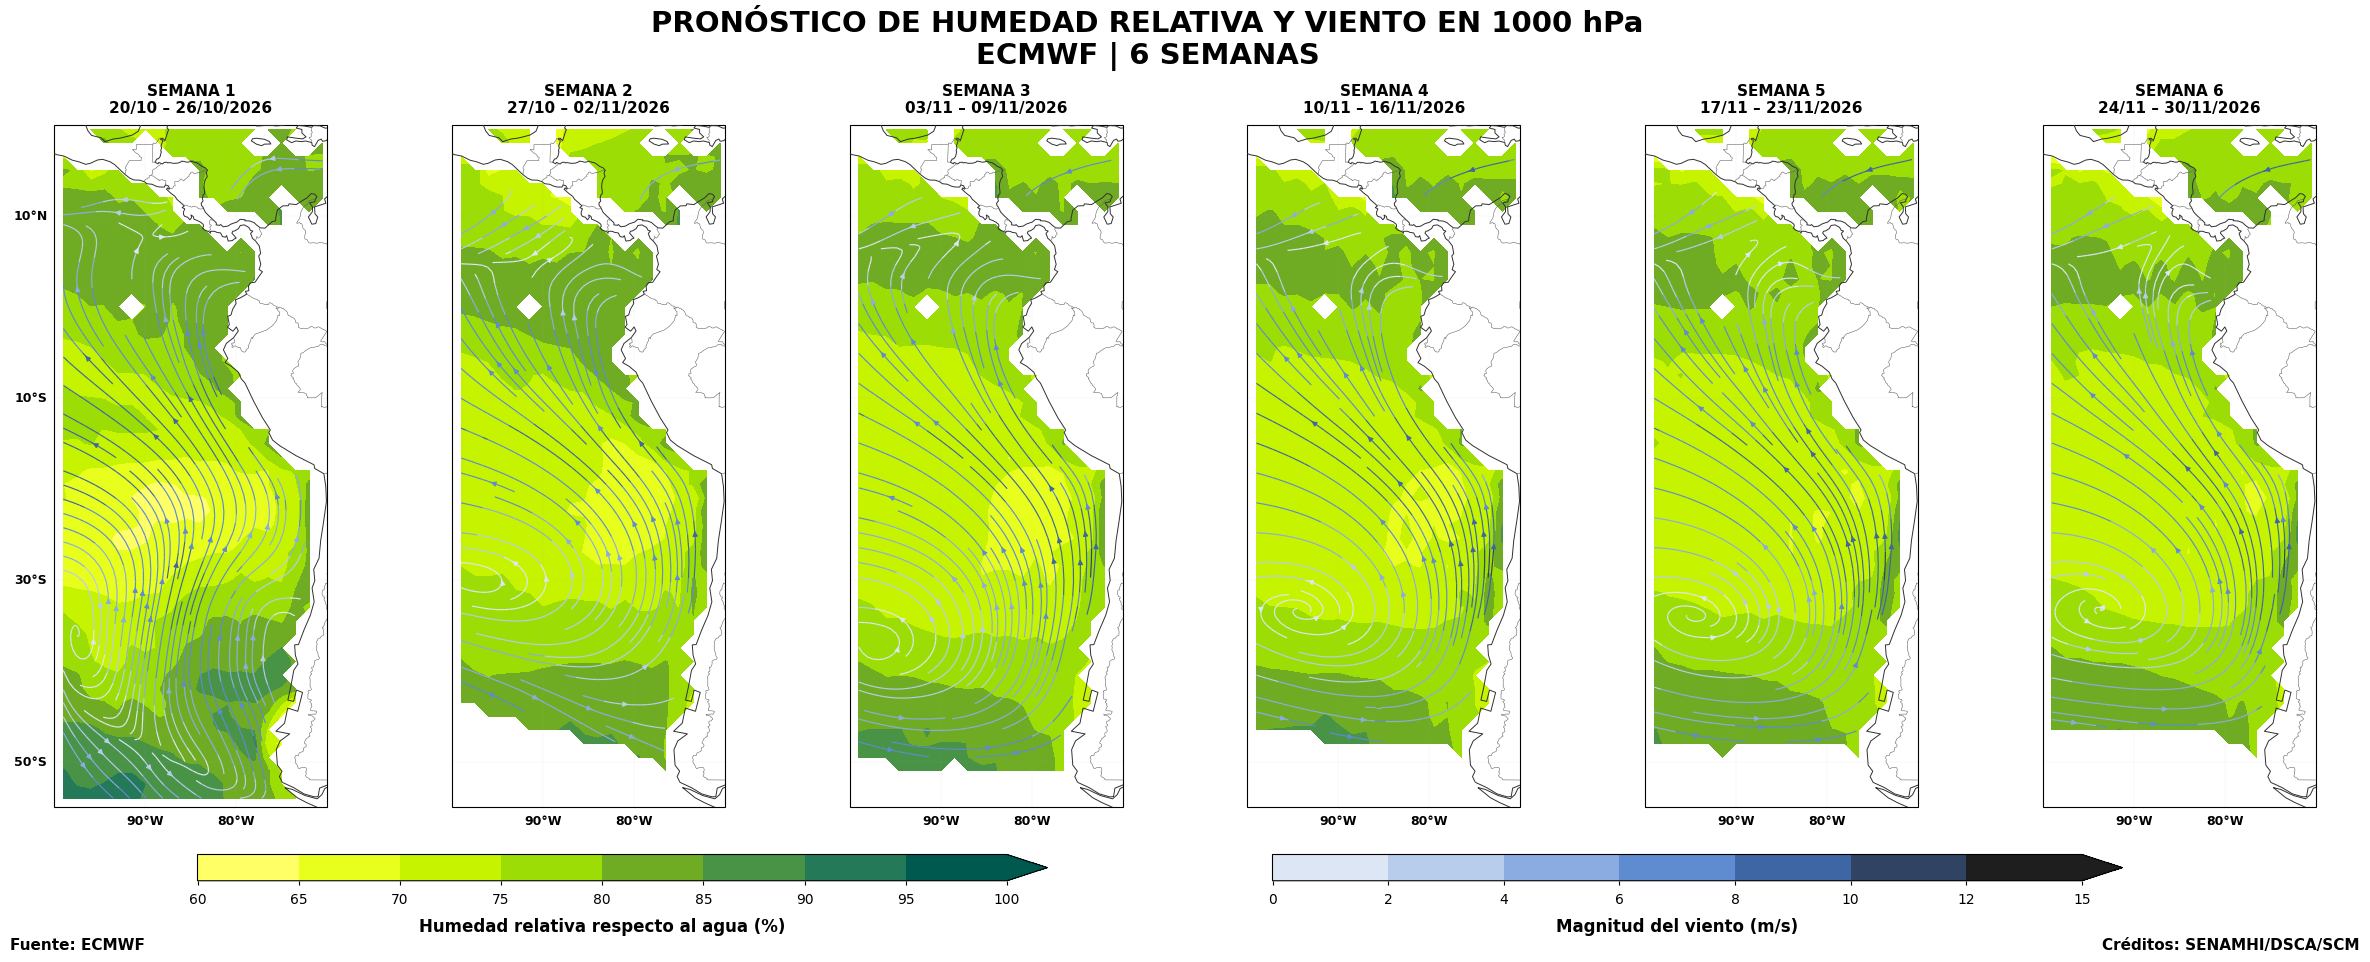


PROCESAMIENTO COMPLETADO
Inicialización: 2026-10-19 00:00:00
Nivel: 1000 hPa
Dominio: -100 -70 -55 20
Semanas: 6
Escala HR: [ 60  65  70  75  80  85  90  95 100]
Escala viento: [ 0  2  4  6  8 10 12 15]
Máximo de viento: 10.62 m/s
Archivo: /content/ECMWF_HR_VIENTO_1000HPA/ECMWF_HR_VIENTO_1000hPa_6SEMANAS_HORIZONTAL_20261019.png


In [9]:
# -*- coding: utf-8 -*-
# ================================================================
# ECMWF | PRONÓSTICO SUBESTACIONAL
# HUMEDAD RELATIVA Y VIENTO EN 1000 hPa
#
# 6 SEMANAS EN UNA SOLA FILA
#
# - Dominio: 100°O–70°O / 55°S–20°N
# - Humedad relativa: 60–100 %
# - Viento: escala automática según máximos semanales
# - Máscara topográfica mediante presión superficial
# - Promedio semanal del ensamble
# - Una sola figura PNG
#
# Fuente: ECMWF
# Créditos: SENAMHI/DSCA/SCM
# ================================================================

# ================================================================
# 0. INSTALACIÓN EN GOOGLE COLAB
# ================================================================

%pip install -q dynamical-catalog cartopy scipy netcdf4

# ================================================================
# 1. LIBRERÍAS
# ================================================================

import os
import numpy as np
import pandas as pd
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.interpolate import RegularGridInterpolator
from matplotlib.cm import ScalarMappable

import dynamical_catalog

# ================================================================
# 2. CONFIGURACIÓN
# ================================================================

CATALOGO = "ecmwf-ifs-ens-forecast-46-day-daily-1-5-degree"

NIVEL = 1000

# Dominio geográfico
LON_MIN, LON_MAX = -100, -70
LAT_MIN, LAT_MAX = -55, 20

# Pronóstico
N_SEMANAS = 6
DIAS_SEMANA = 7

# Máscara física
MARGEN_PS_HPA = 0.0
FRACCION_MINIMA = 0.90

# Líneas de corriente
DENSIDAD = 1.6
RESOLUCION_GRAFICA = 0.5

# Escala de humedad relativa
NIVELES_HR = np.arange(60, 101, 5)

# Salida
OUTPUT_DIR = "/content/ECMWF_HR_VIENTO_1000HPA"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ================================================================
# 3. ABRIR DATOS ECMWF
# ================================================================

print("=" * 75)
print("ECMWF | HUMEDAD RELATIVA Y VIENTO EN 1000 hPa")
print("=" * 75)

ds = dynamical_catalog.open(
    CATALOGO,
    group="pressure_level",
    chunks=None
)

VARIABLES = [
    "wind_u",
    "wind_v",
    "temperature",
    "specific_humidity"
]

for var in VARIABLES:
    if var not in ds:
        raise ValueError(f"Variable no disponible: {var}")

# Inicialización más reciente
INIT_TIME = ds.init_time.values[-1]
INIT = pd.Timestamp(INIT_TIME)

print("Inicialización:", INIT)

if NIVEL not in ds.pressure_level.values:
    raise ValueError(f"Nivel {NIVEL} hPa no disponible")

datos = ds[VARIABLES].sel(
    init_time=INIT_TIME,
    pressure_level=NIVEL
)

# ================================================================
# 4. PREPARAR COORDENADAS
# ================================================================

def preparar_coordenadas(obj):

    if float(obj.longitude.max()) > 180:
        obj = obj.assign_coords(
            longitude=((obj.longitude + 180) % 360) - 180
        )

    obj = obj.sortby("longitude")
    obj = obj.sortby("latitude")

    obj = obj.sel(
        longitude=slice(LON_MIN, LON_MAX),
        latitude=slice(LAT_MIN, LAT_MAX)
    )

    return obj


datos = preparar_coordenadas(datos)

# ================================================================
# 5. SELECCIONAR 42 DÍAS
# ================================================================

plazos = pd.timedelta_range(
    start="1D",
    periods=N_SEMANAS * DIAS_SEMANA,
    freq="D"
)

disponibles = pd.to_timedelta(datos.lead_time.values)
faltantes = plazos.difference(disponibles)

if len(faltantes) > 0:
    raise ValueError(f"Faltan plazos diarios: {faltantes}")

datos = datos.sel(lead_time=plazos)

# ================================================================
# 6. PRESIÓN SUPERFICIAL
# ================================================================

print("\nAbriendo presión superficial...")

ds_sup = dynamical_catalog.open(
    CATALOGO,
    chunks=None
)

if "pressure_surface" not in ds_sup:
    raise ValueError("No se encontró pressure_surface")

ps = ds_sup["pressure_surface"].sel(
    init_time=INIT_TIME
)

ps = preparar_coordenadas(ps)
ps = ps.sel(lead_time=plazos)

# Verificar coincidencia de coordenadas
datos, ps = xr.align(datos, ps, join="exact")

# ================================================================
# 7. VERIFICAR UNIDADES
# ================================================================

def unidades(da):
    return str(
        da.attrs.get("units", "")
    ).strip().lower().replace(" ", "")


unidad_t = unidades(datos["temperature"])
unidad_q = unidades(datos["specific_humidity"])
unidad_u = unidades(datos["wind_u"])
unidad_v = unidades(datos["wind_v"])
unidad_ps = unidades(ps)

print("\nUNIDADES")
print("Temperatura:", unidad_t)
print("Humedad específica:", unidad_q)
print("Viento U:", unidad_u)
print("Viento V:", unidad_v)
print("Presión superficial:", unidad_ps)

UNIDADES_K = {"k", "kelvin", "degk", "degree_kelvin"}
UNIDADES_C = {
    "c", "degc", "celsius", "degree_celsius",
    "degrees_celsius", "°c"
}
UNIDADES_Q = {"kg/kg", "kgkg-1", "kgkg^-1", "1"}
UNIDADES_V = {"m/s", "ms-1", "ms^-1", "m*s-1"}

if unidad_t not in UNIDADES_K | UNIDADES_C:
    raise ValueError(f"Unidad de temperatura no reconocida: {unidad_t}")

if unidad_q not in UNIDADES_Q:
    raise ValueError(f"Unidad de humedad no reconocida: {unidad_q}")

if unidad_u not in UNIDADES_V or unidad_v not in UNIDADES_V:
    raise ValueError("Unidades de viento no reconocidas")

if unidad_ps in {"pa", "pascal", "pascals"}:
    ps_hpa = ps / 100.0
elif unidad_ps in {"hpa", "hectopascal", "hectopascals"}:
    ps_hpa = ps
else:
    raise ValueError(f"Unidad de presión no reconocida: {unidad_ps}")

# La máscara requiere los mismos miembros y días
# para evitar comparaciones incorrectas.
for dim in ["ensemble_member", "lead_time"]:
    if dim not in ps_hpa.dims:
        raise ValueError(
            f"pressure_surface no contiene la dimensión {dim}"
        )

# ================================================================
# 8. FUNCIÓN HUMEDAD RELATIVA
# ================================================================

def calcular_hr_agua(q, T, nivel_hpa):

    """
    Humedad relativa respecto al agua.
    Murphy y Koop (2005).

    q: kg/kg
    T: Kelvin
    p: hPa
    """

    p = nivel_hpa * 100.0

    e = q * p / (0.622 + 0.378 * q)

    ln_es = (
        54.842763
        - 6763.22 / T
        - 4.210 * np.log(T)
        + 0.000367 * T
        + np.tanh(0.0415 * (T - 218.8)) * (
            53.878
            - 1331.22 / T
            - 9.44523 * np.log(T)
            + 0.014025 * T
        )
    )

    es = np.exp(ln_es)

    return 100.0 * e / es

# ================================================================
# 9. PALETA HUMEDAD RELATIVA: 60–100 %
# ================================================================

COLORES_HR_BASE = [
    "#FFFF66",
    "#DFFF00",
    "#A6E600",
    "#66A329",
    "#32875C",
    "#00594F"
]

cmap_hr_continuo = mcolors.LinearSegmentedColormap.from_list(
    "humedad_ecmwf",
    COLORES_HR_BASE,
    N=256
)

COLORES_HR = cmap_hr_continuo(
    np.linspace(0, 1, len(NIVELES_HR) - 1)
)

CMAP_HR = mcolors.ListedColormap(COLORES_HR)
CMAP_HR.set_under("#FFFFFF")
CMAP_HR.set_over("#00594F")

NORM_HR = mcolors.BoundaryNorm(
    NIVELES_HR,
    CMAP_HR.N
)

# ================================================================
# 10. INTERPOLACIÓN DE VIENTO
# ================================================================

def interpolar_viento(lon, lat, U, V):

    lon_n = np.arange(
        lon.min(),
        lon.max() + 0.001,
        RESOLUCION_GRAFICA
    )

    lat_n = np.arange(
        lat.min(),
        lat.max() + 0.001,
        RESOLUCION_GRAFICA
    )

    LON_N, LAT_N = np.meshgrid(lon_n, lat_n)

    puntos = np.column_stack([
        LAT_N.ravel(),
        LON_N.ravel()
    ])

    mascara = np.isfinite(U) & np.isfinite(V)

    # Relleno temporal para interpolar, sin inventar
    # viento en las zonas topográficamente inválidas.
    U_aux = np.where(mascara, U, 0.0)
    V_aux = np.where(mascara, V, 0.0)

    interp_u = RegularGridInterpolator(
        (lat, lon),
        U_aux,
        method="linear",
        bounds_error=False,
        fill_value=np.nan
    )

    interp_v = RegularGridInterpolator(
        (lat, lon),
        V_aux,
        method="linear",
        bounds_error=False,
        fill_value=np.nan
    )

    interp_mascara = RegularGridInterpolator(
        (lat, lon),
        mascara.astype(float),
        method="linear",
        bounds_error=False,
        fill_value=0
    )

    U_N = interp_u(puntos).reshape(LON_N.shape)
    V_N = interp_v(puntos).reshape(LON_N.shape)

    fraccion = interp_mascara(puntos).reshape(LON_N.shape)

    # Solo permitir interpolación dentro de celdas
    # cuyos cuatro vértices tienen viento válido.
    mascara_nueva = fraccion >= 0.999

    U_N = np.where(mascara_nueva, U_N, np.nan)
    V_N = np.where(mascara_nueva, V_N, np.nan)

    return lon_n, lat_n, U_N, V_N

# ================================================================
# 11. CÁLCULOS SEMANALES
# ================================================================

lon = datos.longitude.values
lat = datos.latitude.values

resultados = []
maximos_viento = []

print("\nCalculando seis semanas...")

for semana in range(N_SEMANAS):

    inicio = semana * DIAS_SEMANA
    fin = inicio + DIAS_SEMANA

    bloque = datos.isel(
        lead_time=slice(inicio, fin)
    ).load()

    ps_semana = ps_hpa.isel(
        lead_time=slice(inicio, fin)
    ).load()

    # ------------------------------------------------------------
    # MÁSCARA FÍSICA POR MIEMBRO Y DÍA
    # ------------------------------------------------------------

    mascara_fisica = (
        ps_semana >= NIVEL + MARGEN_PS_HPA
    )

    fraccion_valida = mascara_fisica.mean(
        dim=["ensemble_member", "lead_time"]
    )

    mascara_final = fraccion_valida >= FRACCION_MINIMA

    # ------------------------------------------------------------
    # VIENTO MEDIO VECTORIAL
    # ------------------------------------------------------------

    U_DA = bloque["wind_u"].where(
        mascara_fisica
    ).mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).where(mascara_final)

    V_DA = bloque["wind_v"].where(
        mascara_fisica
    ).mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).where(mascara_final)

    U = U_DA.transpose("latitude", "longitude").values
    V = V_DA.transpose("latitude", "longitude").values

    VEL = np.hypot(U, V)

    # ------------------------------------------------------------
    # HUMEDAD RELATIVA
    # ------------------------------------------------------------

    q = bloque["specific_humidity"]
    T = bloque["temperature"]

    if unidad_t in UNIDADES_C:
        T_K = T + 273.15
    else:
        T_K = T

    HR_DIARIA = calcular_hr_agua(
        q,
        T_K,
        NIVEL
    ).where(mascara_fisica)

    HR_DA = HR_DIARIA.mean(
        dim=["ensemble_member", "lead_time"],
        skipna=True
    ).where(mascara_final)

    HR = HR_DA.transpose(
        "latitude", "longitude"
    ).values

    # ------------------------------------------------------------
    # FECHAS
    # ------------------------------------------------------------

    fecha_inicio = INIT + plazos[inicio]
    fecha_fin = INIT + plazos[fin - 1]

    titulo = (
        f"SEMANA {semana + 1}\n"
        f"{fecha_inicio:%d/%m} – {fecha_fin:%d/%m/%Y}"
    )

    # Estadísticas
    if np.isfinite(VEL).any():
        vmax = float(np.nanmax(VEL))
        vmedia = float(np.nanmean(VEL))
    else:
        vmax = np.nan
        vmedia = np.nan

    maximos_viento.append(vmax)

    resultados.append({
        "U": U,
        "V": V,
        "VEL": VEL,
        "HR": HR,
        "titulo": titulo
    })

    print(
        f"Semana {semana + 1} | "
        f"Viento medio: {vmedia:.2f} m/s | "
        f"Máximo: {vmax:.2f} m/s"
    )

# ================================================================
# 12. ESCALA AUTOMÁTICA DEL VIENTO
# ================================================================

maximos_validos = [
    x for x in maximos_viento if np.isfinite(x)
]

if not maximos_validos:
    raise ValueError("No hay valores válidos de viento")

maximo_global = max(maximos_validos)

NIVELES_VIENTO = [0, 2, 4, 6, 8, 10, 12, 15]

for limite in [20, 25, 30]:
    if maximo_global > NIVELES_VIENTO[-1]:
        NIVELES_VIENTO.append(limite)

if maximo_global > 30:
    limite_final = int(5 * np.ceil(maximo_global / 5))
    NIVELES_VIENTO.extend(
        range(35, limite_final + 1, 5)
    )

NIVELES_VIENTO = np.array(NIVELES_VIENTO)

print("\nMáximo global:", maximo_global, "m/s")
print("Escala de viento:", NIVELES_VIENTO)

# ================================================================
# 13. PALETA DEL VIENTO
# ================================================================

COLORES_VIENTO_BASE = [
    "#DCE6F5",
    "#BED0ED",
    "#97B5E4",
    "#729ADB",
    "#4D7DC6",
    "#365A93",
    "#303F5A",
    "#1E1E1E"
]

cmap_v_continuo = mcolors.LinearSegmentedColormap.from_list(
    "viento_ecmwf",
    COLORES_VIENTO_BASE,
    N=256
)

n_intervalos = len(NIVELES_VIENTO) - 1

COLORES_VIENTO = cmap_v_continuo(
    np.linspace(0, 1, n_intervalos)
)

CMAP_VIENTO = mcolors.ListedColormap(
    COLORES_VIENTO
)

CMAP_VIENTO.set_under(COLORES_VIENTO[0])
CMAP_VIENTO.set_over(COLORES_VIENTO[-1])

NORM_VIENTO = mcolors.BoundaryNorm(
    NIVELES_VIENTO,
    CMAP_VIENTO.N
)

# ================================================================
# 14. FIGURA PANORÁMICA - SEIS MAPAS EN UNA FILA
# ================================================================

fig, axes = plt.subplots(
    1, 6,
    figsize=(25, 10.5),
    subplot_kw={
        "projection": ccrs.PlateCarree()
    },
    facecolor="white"
)

for i, (ax, resultado) in enumerate(
    zip(axes, resultados)
):

    HR = resultado["HR"]
    U = resultado["U"]
    V = resultado["V"]

    # ------------------------------------------------------------
    # HUMEDAD RELATIVA
    # ------------------------------------------------------------

    HR_PLOT = np.ma.masked_invalid(HR)
    HR_PLOT = np.ma.masked_less(
        HR_PLOT,
        NIVELES_HR[0]
    )

    ax.contourf(
        lon,
        lat,
        HR_PLOT,
        levels=NIVELES_HR,
        cmap=CMAP_HR,
        norm=NORM_HR,
        extend="max",
        transform=ccrs.PlateCarree(),
        zorder=1
    )

    # ------------------------------------------------------------
    # VIENTO
    # ------------------------------------------------------------

    lon_n, lat_n, U_N, V_N = interpolar_viento(
        lon, lat, U, V
    )

    VEL_N = np.hypot(U_N, V_N)

    ax.streamplot(
        lon_n,
        lat_n,
        np.ma.masked_invalid(U_N),
        np.ma.masked_invalid(V_N),
        color=np.ma.masked_invalid(VEL_N),
        cmap=CMAP_VIENTO,
        norm=NORM_VIENTO,
        density=DENSIDAD,
        linewidth=0.85,
        arrowsize=0.75,
        minlength=0.2,
        transform=ccrs.PlateCarree(),
        zorder=3
    )

    # ------------------------------------------------------------
    # COSTAS Y FRONTERAS
    # ------------------------------------------------------------

    ax.coastlines(
        resolution="110m",
        linewidth=0.7,
        color="#303030",
        zorder=4
    )

    ax.add_feature(
        cfeature.BORDERS,
        linewidth=0.4,
        edgecolor="#666666",
        zorder=4
    )

    ax.set_extent(
        [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX],
        crs=ccrs.PlateCarree()
    )

    # ------------------------------------------------------------
    # COORDENADAS
    # ------------------------------------------------------------

    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.3,
        linestyle="--",
        alpha=0.25
    )

    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (i == 0)

    gl.xlocator = mticker.FixedLocator(
        [-100, -90, -80, -70]
    )

    gl.ylocator = mticker.FixedLocator(
        [-50, -30, -10, 10]
    )

    gl.xlabel_style = {
        "size": 9,
        "weight": "bold"
    }

    gl.ylabel_style = {
        "size": 9,
        "weight": "bold"
    }

    # ------------------------------------------------------------
    # TÍTULO SEMANAL
    # ------------------------------------------------------------

    ax.set_title(
        resultado["titulo"],
        fontsize=11,
        fontweight="bold",
        pad=9
    )

# ================================================================
# 15. DISTRIBUCIÓN GENERAL
# ================================================================

fig.subplots_adjust(
    left=0.045,
    right=0.985,
    bottom=0.19,
    top=0.84,
    wspace=0.10
)

fig.suptitle(
    "PRONÓSTICO DE HUMEDAD RELATIVA Y VIENTO EN 1000 hPa\n"
    "ECMWF | 6 SEMANAS",
    fontsize=21,
    fontweight="bold",
    y=0.95
)

# ================================================================
# 16. BARRA DE HUMEDAD RELATIVA
# ================================================================

cax_hr = fig.add_axes([
    0.12, 0.12, 0.34, 0.025
])

sm_hr = ScalarMappable(
    norm=NORM_HR,
    cmap=CMAP_HR
)
sm_hr.set_array([])

cb_hr = fig.colorbar(
    sm_hr,
    cax=cax_hr,
    orientation="horizontal",
    ticks=NIVELES_HR,
    boundaries=NIVELES_HR,
    spacing="uniform",
    extend="max"
)

cb_hr.set_label(
    "Humedad relativa respecto al agua (%)",
    fontsize=12,
    fontweight="bold",
    labelpad=8
)

cb_hr.ax.tick_params(
    labelsize=10,
    length=3,
    pad=5
)

# ================================================================
# 17. BARRA DE MAGNITUD DEL VIENTO
# ================================================================

cax_v = fig.add_axes([
    0.55, 0.12, 0.34, 0.025
])

sm_v = ScalarMappable(
    norm=NORM_VIENTO,
    cmap=CMAP_VIENTO
)
sm_v.set_array([])

cb_v = fig.colorbar(
    sm_v,
    cax=cax_v,
    orientation="horizontal",
    ticks=NIVELES_VIENTO,
    boundaries=NIVELES_VIENTO,
    spacing="uniform",
    extend="max"
)

cb_v.set_label(
    "Magnitud del viento (m/s)",
    fontsize=12,
    fontweight="bold",
    labelpad=8
)

cb_v.ax.tick_params(
    labelsize=10,
    length=3,
    pad=5
)

# ================================================================
# 18. FUENTE Y CRÉDITOS
# ================================================================

fig.text(
    0.045, 0.055,
    "Fuente: ECMWF",
    fontsize=11,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.985, 0.055,
    "Créditos: SENAMHI/DSCA/SCM",
    fontsize=11,
    fontweight="bold",
    ha="right"
)

# ================================================================
# 19. GUARDAR SOLO PNG
# ================================================================

archivo = os.path.join(
    OUTPUT_DIR,
    (
        f"ECMWF_HR_VIENTO_1000hPa_"
        f"6SEMANAS_HORIZONTAL_{INIT:%Y%m%d}.png"
    )
)

plt.savefig(
    archivo,
    dpi=250,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ================================================================
# 20. RESUMEN
# ================================================================

print("\n" + "=" * 75)
print("PROCESAMIENTO COMPLETADO")
print("=" * 75)

print("Inicialización:", INIT)
print("Nivel:", NIVEL, "hPa")
print("Dominio:", LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)
print("Semanas:", N_SEMANAS)
print("Escala HR:", NIVELES_HR)
print("Escala viento:", NIVELES_VIENTO)
print("Máximo de viento:", round(maximo_global, 2), "m/s")
print("Archivo:", archivo)